<a href="https://colab.research.google.com/github/YikeCahya/PCVK_Ganjil_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Segmentasi Citra dengan Thresholding
Pengolahan Citra dan Visi Komputer – Praktikum P7

Nama: Yulike Dwi Nurcahyani

NIM: 244107020146

Kelas: TI - 3E

## D1.1 – Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## D1.2 – Import library

In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Folder gambar di Drive (sesuaikan bila berbeda)
BASE = '/content/drive/MyDrive/Kuliah/PCVK/Images/'

## D1.3 – Global Threshold manual (threshold = 200)
Lima jenis global threshold dibuat dengan NumPy (`np.where`), tanpa `cv.threshold()`.

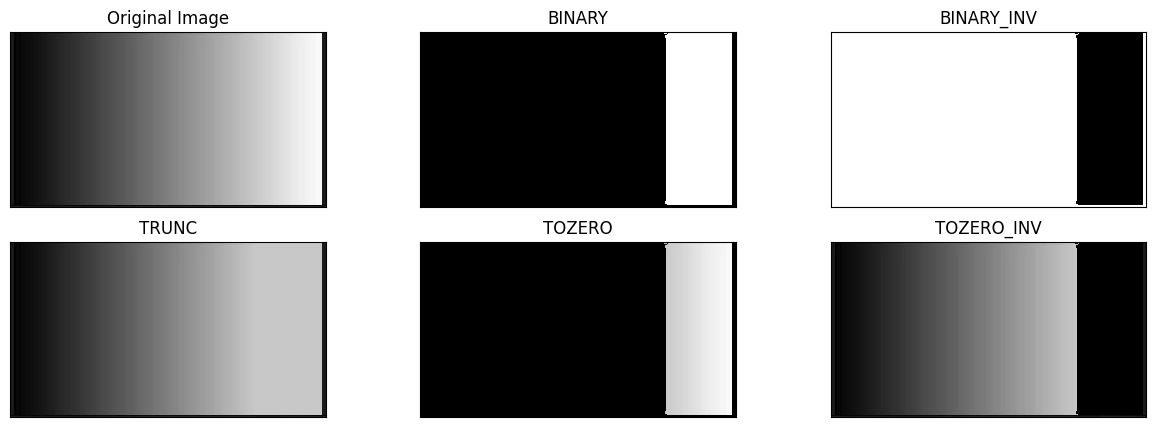

In [ ]:
img = cv.imread(BASE + 'gradient.webp', 0)   # grayscale
thresh = 200
maxval = 255

def global_threshold(src, thresh, maxval, jenis):
    if jenis == 'BINARY':
        dst = np.where(src > thresh, maxval, 0)
    elif jenis == 'BINARY_INV':
        dst = np.where(src > thresh, 0, maxval)
    elif jenis == 'TRUNC':
        dst = np.where(src > thresh, thresh, src)
    elif jenis == 'TOZERO':
        dst = np.where(src > thresh, src, 0)
    elif jenis == 'TOZERO_INV':
        dst = np.where(src > thresh, 0, src)
    return dst.astype(np.uint8)

jenis_list = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
titles = ['Original Image'] + jenis_list
images = [img] + [global_threshold(img, thresh, maxval, j) for j in jenis_list]

plt.figure(figsize=(15,5))
for i in range(len(images)):
    plt.subplot(2,3,i+1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## D1.4 – Adaptive Threshold manual (Mean & Gaussian)
Tanpa `cv.threshold()`, `cv.adaptiveThreshold()`, maupun filter siap pakai.
Rata-rata lokal dihitung manual: jendela 11×11 digeser, lalu setiap geseran dikalikan bobotnya
(bobot seragam untuk Mean, bobot Gaussian σ=2 untuk Gaussian). Tepi citra memakai replikasi piksel.

Ketentuan: global T=127, jendela 11×11, C=2, σ=2.

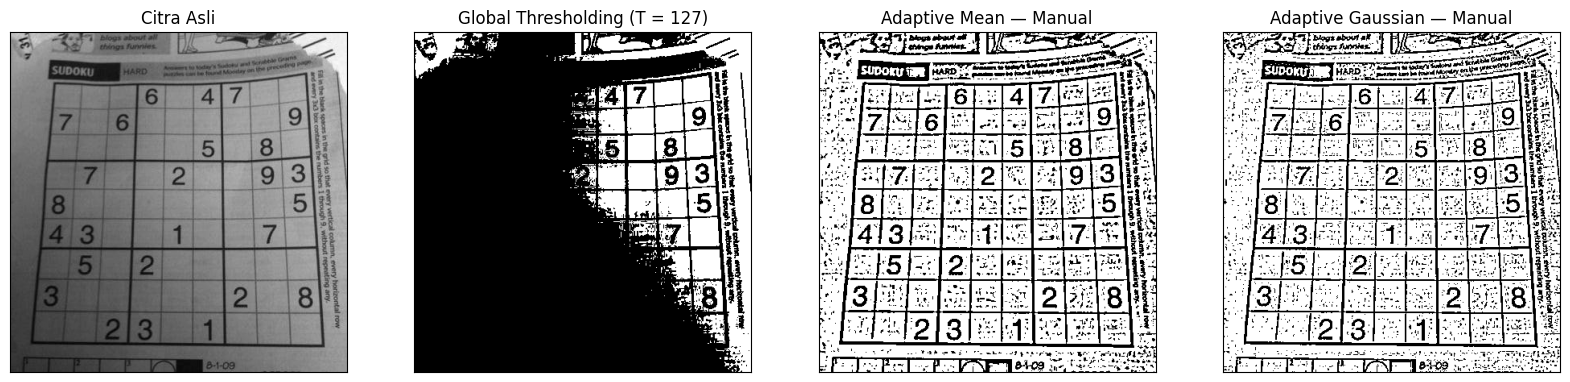

In [ ]:
gray = cv.imread(BASE + 'sudoku-original.jpg', 0)

b = 11        # ukuran jendela
C = 2         # konstanta
sigma = 2     # untuk Gaussian

def kernel_mean(b):
    return np.ones((b, b)) / (b * b)

def kernel_gaussian(b, sigma):
    r = b // 2
    ax = np.arange(-r, r + 1)
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    k = np.outer(g, g)
    return k / k.sum()

def local_average(src, kernel):
    # rata-rata berbobot pada jendela b x b untuk setiap piksel
    k = kernel.shape[0]
    r = k // 2
    H, W = src.shape
    pad = np.pad(src.astype(np.float64), r, mode='edge')
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(k):
        for j in range(k):
            out += kernel[i, j] * pad[i:i + H, j:j + W]
    return out

def adaptive_manual(src, kernel, C):
    T = local_average(src, kernel) - C          # T(x,y) = rata-rata lokal - C
    return np.where(src > T, 255, 0).astype(np.uint8)

th_global = np.where(gray > 127, 255, 0).astype(np.uint8)
th_mean = adaptive_manual(gray, kernel_mean(b), C)
th_gauss = adaptive_manual(gray, kernel_gaussian(b, sigma), C)

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th_global, th_mean, th_gauss]

plt.figure(figsize=(20,6))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1), plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## D1.5 – Otsu Thresholding tanpa library
**A.** `lena_gs_lc2.jpg` dibandingkan dengan global threshold 127 (dan dengan Otsu library, nilainya dicetak).
**B.** Citra KTP sendiri.

Kelas background = intensitas < t, foreground = intensitas ≥ t. t dipilih yang membuat *between-class variance* terbesar.

Otsu manual: 88 | Otsu library (cv.THRESH_OTSU): 87.0


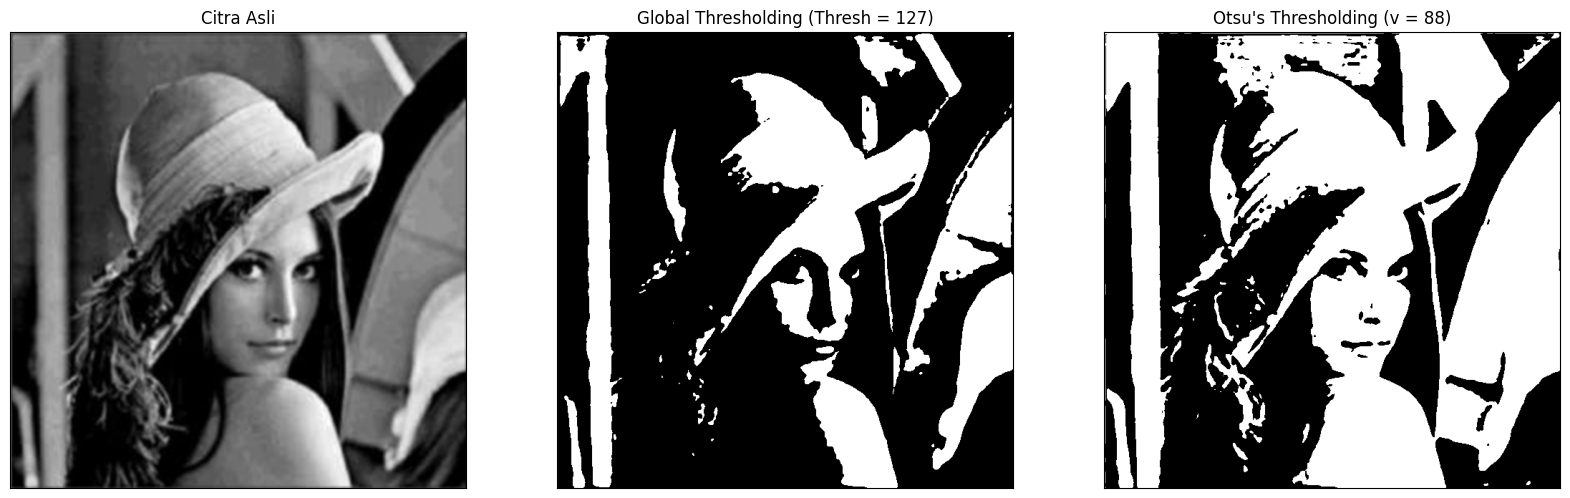

In [ ]:
def otsu(gray):
    hist, _ = np.histogram(gray, bins=256, range=(0, 256))
    p = hist / hist.sum()                       # probabilitas tiap intensitas
    i = np.arange(256)

    final_thresh, final_value = -1, -1
    for t in range(1, 256):
        Wb, Wf = p[:t].sum(), p[t:].sum()       # bobot background & foreground
        if Wb == 0 or Wf == 0:
            continue
        mub = (i[:t] * p[:t]).sum() / Wb        # mean background
        muf = (i[t:] * p[t:]).sum() / Wf        # mean foreground
        value = Wb * Wf * (mub - muf) ** 2      # between-class variance
        if value > final_value:
            final_thresh, final_value = t, value

    final_img = np.where(gray >= final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

def bandingkan_otsu(filename, thresh=127):
    img = cv.imread(filename, 0)
    blur = cv.GaussianBlur(img, (5,5), 0)

    otsu_biner, otsu_thresh = otsu(blur)
    ret_lib, _ = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    print(f'Otsu manual: {otsu_thresh} | Otsu library (cv.THRESH_OTSU): {ret_lib}')

    ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
    titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')',
              "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"]
    citra3 = [blur, th1, otsu_biner]

    plt.figure(figsize=(20,15))
    for i in range(len(citra3)):
        plt.subplot(1,3,i+1), plt.imshow(citra3[i], 'gray')
        plt.title(titles[i])
        plt.xticks([]), plt.yticks([])
    plt.show()
    return blur

# A. Lena low contrast
blur_lena = bandingkan_otsu(BASE + 'lena_gs_lc2.png')

Otsu manual: 116 | Otsu library (cv.THRESH_OTSU): 115.0


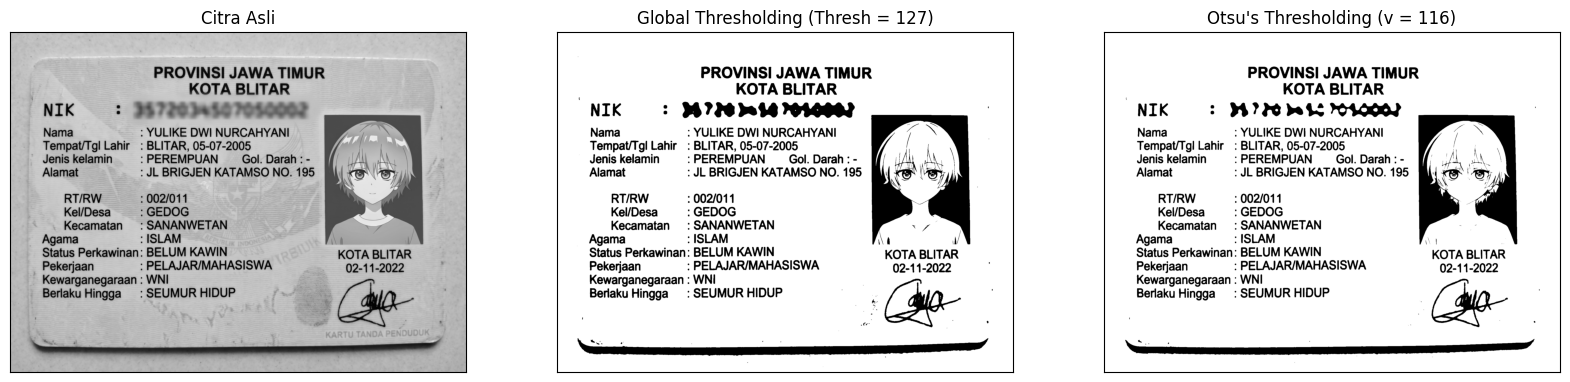

In [ ]:
# B. KTP sendiri
blur_ktp = bandingkan_otsu(BASE + 'KTP IKE ai.jpg')

### Pertanyaan: mengapa Binary Threshold (T=127) pada Lena semuanya hitam?
Cek histogram dan cari ambang yang masih menampilkan Lena.

Intensitas min / max citra Lena: 0 / 252


/tmp/ipykernel_1597/2056500367.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur_lena.ravel(), 256, [0,256])


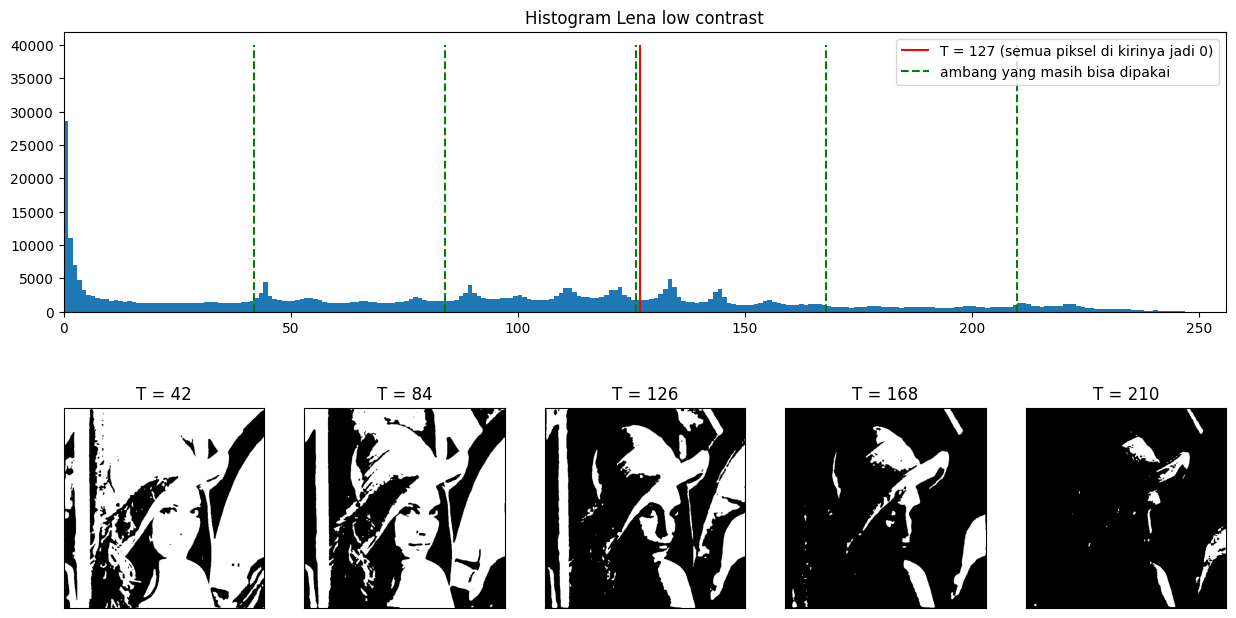

In [ ]:
print('Intensitas min / max citra Lena:', blur_lena.min(), '/', blur_lena.max())

# Ambang yang masih memperlihatkan Lena: antara min dan max
kandidat = np.unique(np.linspace(blur_lena.min(), blur_lena.max(), 7)[1:-1].astype(int))

plt.figure(figsize=(15,8))
plt.subplot(2,1,1)
plt.hist(blur_lena.ravel(), 256, [0,256])
plt.vlines(127, 0, 40000, colors='red', label='T = 127 (semua piksel di kirinya jadi 0)')
plt.vlines(kandidat, 0, 40000, colors='green', linestyles='dashed', label='ambang yang masih bisa dipakai')
plt.xlim(0,256); plt.title('Histogram Lena low contrast'); plt.legend()

for i, T in enumerate(kandidat):
    plt.subplot(2, len(kandidat), len(kandidat) + i + 1)
    plt.imshow(np.where(blur_lena > T, 255, 0), 'gray')
    plt.title(f'T = {T}'); plt.xticks([]), plt.yticks([])
plt.show()

**Jawaban:**
Citra Lena ini *low contrast*: seluruh intensitasnya hanya berada di rentang sempit sekitar **85–108**, jadi histogramnya menumpuk di sisi kiri garis T=127. Binary threshold mengubah piksel dengan nilai > T menjadi 255 dan sisanya menjadi 0. Karena **tidak ada satu pun piksel yang nilainya > 127**, semua piksel jatuh ke kelompok "≤ T" dan menjadi 0 (hitam semua).

Agar Lena masih terlihat, ambang harus berada **di dalam rentang intensitas citra**, yaitu kira-kira **T ≈ 85 sampai 107** (nilai pasti lihat output min/max di atas). Nilai yang paling masuk akal adalah sekitar **92–93**, sama dengan hasil Otsu, karena memotong histogram menjadi dua bagian yang seimbang.

**Perbandingan dengan KTP:** Nilai Otsu pada KTP jauh lebih tinggi daripada Lena, dan global T=127 masih bisa memisahkan teks, tetapi latar biru muda/foto ikut berubah sehingga hasilnya berbeda dengan Otsu.

## D1.6 – Segmentasi berbasis region pada `data.coins()`
Tiga seed: **di dalam koin**, **di latar**, dan **tepat di tepi koin**. Setiap seed dijalankan dengan T = 5, 20, 60 → grid 3×3 (seed × T).

**A.** Region growing manual (BFS, 4 ketetanggaan, kriteria |I(q) − μ_region| < T).

Seed dalam koin (baris, kolom): (55, 40) | intensitas: 197
Seed di latar (baris, kolom): (20, 60) | intensitas: 120
Seed di tepi koin (baris, kolom): (55, 22) | intensitas: 170


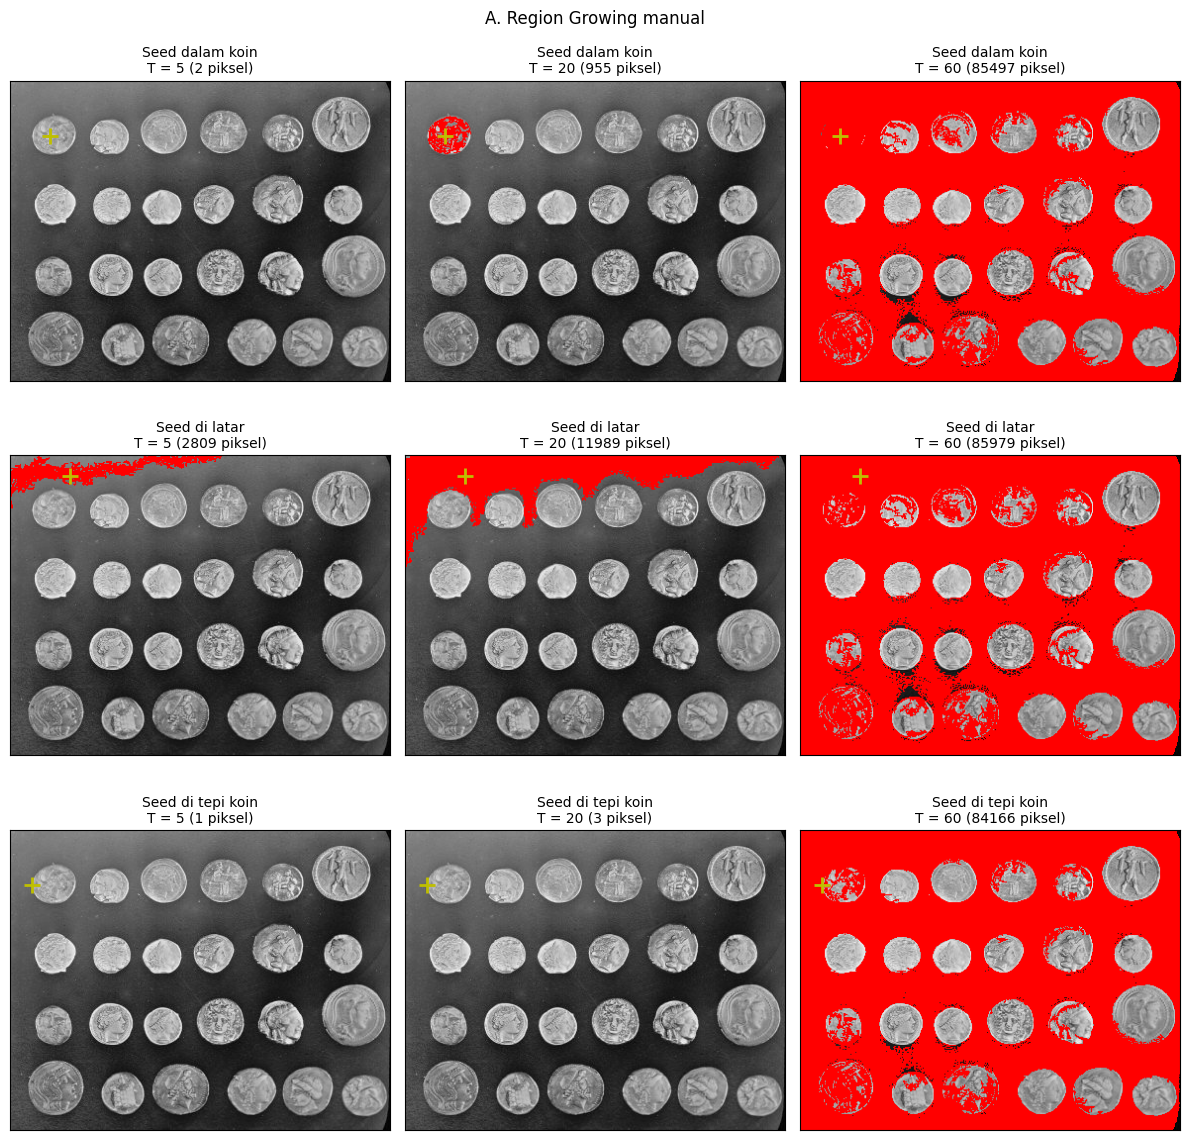

In [ ]:
gray = data.coins()          # grayscale 303 x 384

seeds = {
    'Seed dalam koin':  (55, 40),
    'Seed di latar':    (20, 60),
    'Seed di tepi koin': (55, 22),
}
T_list = [5, 20, 60]

for nama, s in seeds.items():
    print(f'{nama} (baris, kolom): {s} | intensitas: {gray[s]}')

def region_growing(gray, seed, T):
    H, W = gray.shape
    g = gray.astype(np.float32)
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    total, n = g[seed], 1                     # untuk rata-rata region
    queue = deque([seed])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ((-1,0), (1,0), (0,-1), (0,1)):
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and not mask[rr, cc]:
                if abs(g[rr, cc] - total / n) < T:
                    mask[rr, cc] = True
                    total += g[rr, cc]
                    n += 1
                    queue.append((rr, cc))
    return mask

def overlay(gray, mask):
    rgb = np.stack([gray] * 3, axis=-1).copy()
    rgb[mask] = [255, 0, 0]
    return rgb

def tampilkan_grid(fungsi, judul):
    plt.figure(figsize=(12,12))
    for i, (nama, s) in enumerate(seeds.items()):
        for j, T in enumerate(T_list):
            mask = fungsi(gray, s, T)
            plt.subplot(3, 3, i*3 + j + 1)
            plt.imshow(overlay(gray, mask))
            plt.plot(s[1], s[0], 'y+', markersize=12, markeredgewidth=2)
            plt.title(f'{nama}\nT = {T} ({mask.sum()} piksel)', fontsize=10)
            plt.xticks([]), plt.yticks([])
    plt.suptitle(judul)
    plt.tight_layout()
    plt.show()

tampilkan_grid(region_growing, 'A. Region Growing manual')

**B.** Dengan `skimage.segmentation.flood()` (fungsi siap pakai), seed dan T yang sama.

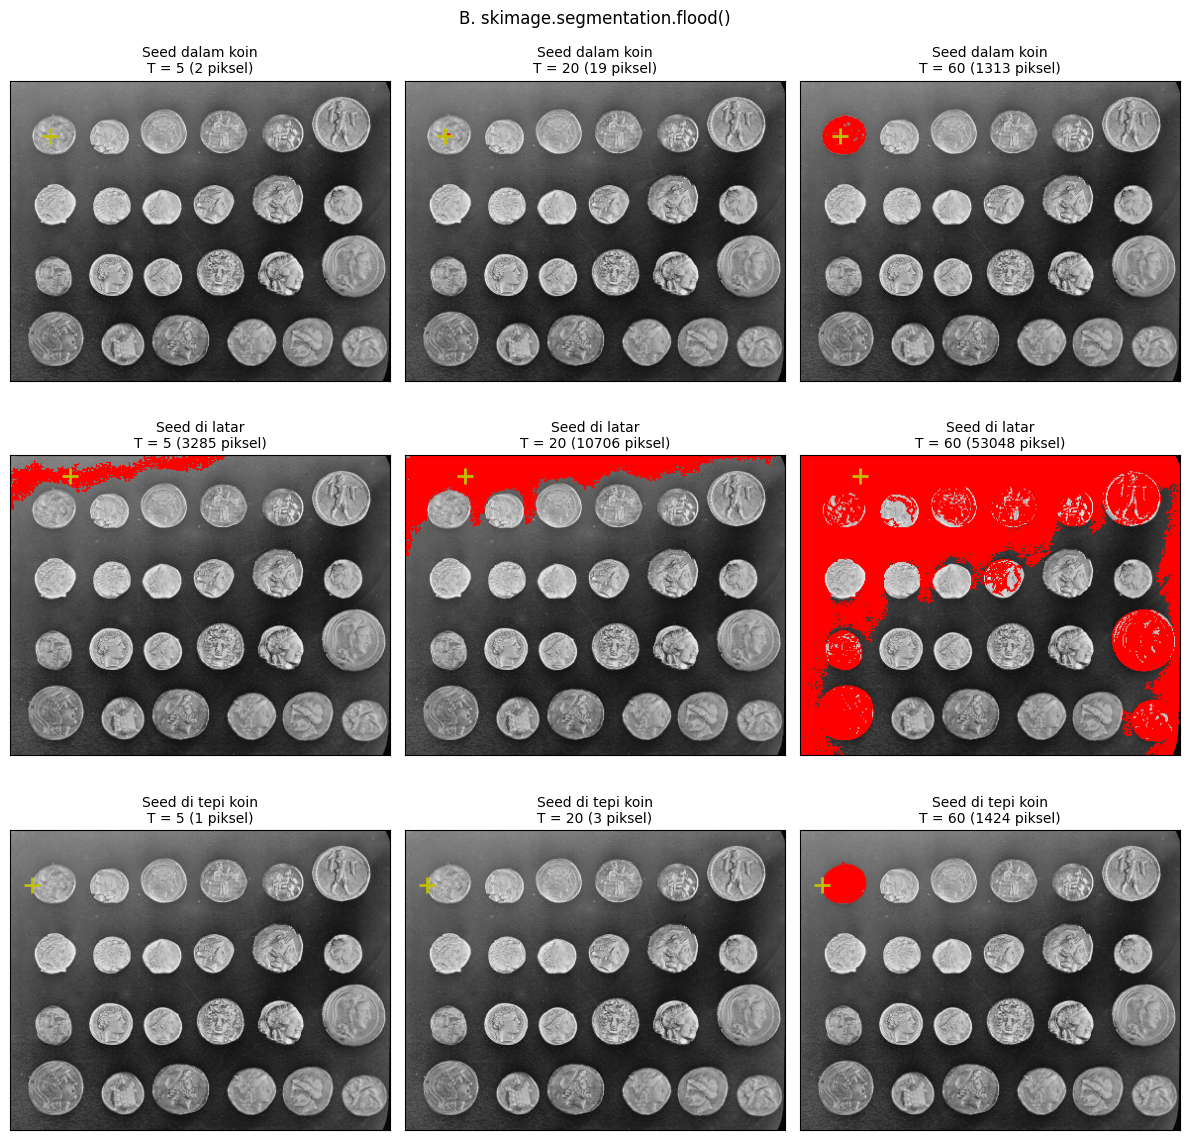

In [ ]:
def region_flood(gray, seed, T):
    return flood(gray, seed_point=seed, tolerance=T, connectivity=1)   # 4 tetangga

tampilkan_grid(region_flood, 'B. skimage.segmentation.flood()')

## D1.7 – Segmentasi warna `ktp_fulan.jpg`: hanya warna biru
K-Means (K=8) pada warna piksel, lalu hasilnya dikonversi ke HSV dan hanya piksel dengan
`H 85–130, S ≥ 25, V ≥ 40` yang ditampilkan.

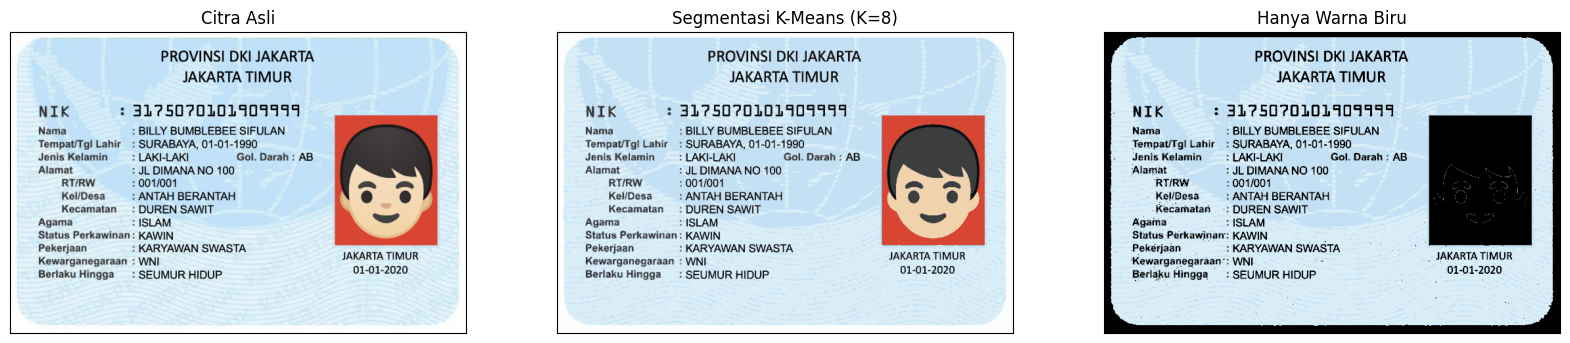

In [ ]:
from sklearn.cluster import KMeans

img_bgr = cv.imread(BASE + 'ktp_fulan.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# K-Means pada piksel (K = 8)
Z = np.float32(img_rgb.reshape((-1, 3)))
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=3)
kmeans.fit(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[kmeans.labels_.flatten()].reshape(img_rgb.shape)

# Ambil hanya warna biru (HSV)
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

hasil_biru = np.zeros_like(segmented_img)
hasil_biru[kelompok_biru] = segmented_img[kelompok_biru]

titles = ['Citra Asli', f'Segmentasi K-Means (K={k})', 'Hanya Warna Biru']
citra = [img_rgb, segmented_img, hasil_biru]
plt.figure(figsize=(20,6))
for i in range(3):
    plt.subplot(1,3,i+1), plt.imshow(citra[i])
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

# D2 – Tugas Kelompok: OCR KTP (warna asli vs Otsu vs Adaptive)
Setiap anggota memakai KTP masing-masing; ganti `ktp_fulan.jpg` dan daftar `acuan` di bawah.

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


### Langkah 1 – Siapkan tiga citra (ukuran sama)

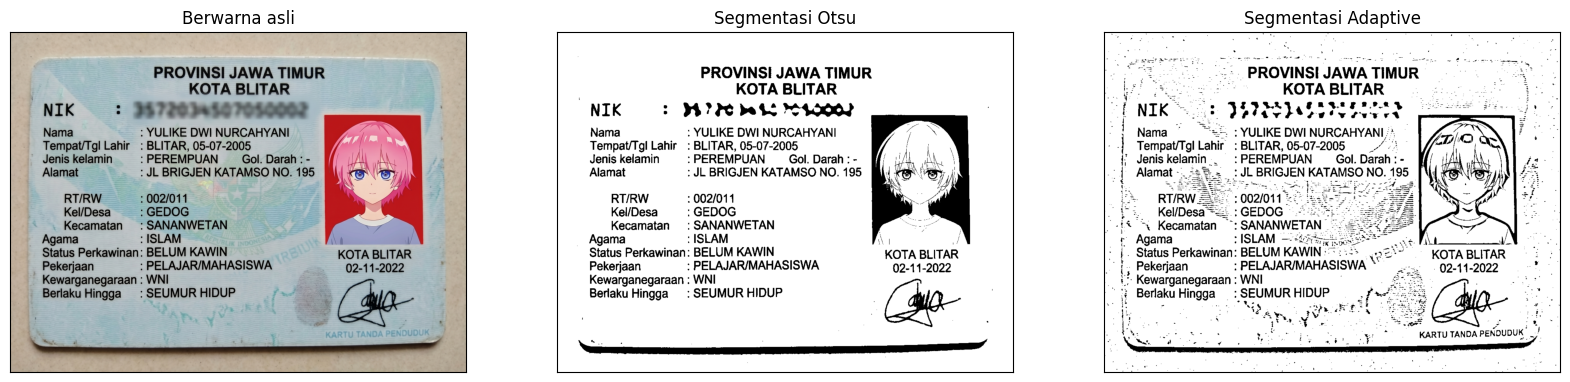

In [ ]:
import re, difflib
import pytesseract
from pytesseract import Output
from IPython.display import display

filename = BASE + 'KTP IKE ai.jpg'     # ganti dengan KTP masing-masing
LANG = 'ind'                          # bahasa sama untuk ketiga citra
PSM = '--psm 6'                       # --psm sama untuk ketiga citra
CONF_MIN = 60                         # batas confidence untuk kotak hijau

img_bgr = cv.imread(filename)
h, w = img_bgr.shape[:2]
img_bgr = cv.resize(img_bgr, (1200, int(1200 * h / w)))      # ukuran sama untuk semua

gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)                # grayscale dulu
_, otsu_img = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
adaptive_img = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)

citra_ocr = {
    'Berwarna asli': cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB),
    'Segmentasi Otsu': otsu_img,
    'Segmentasi Adaptive': adaptive_img,
}

plt.figure(figsize=(20,6))
for i, (nama, im) in enumerate(citra_ocr.items()):
    plt.subplot(1,3,i+1), plt.imshow(im, 'gray' if im.ndim == 2 else None)
    plt.title(nama), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 2 – Baca teks dengan `image_to_string()`

In [ ]:
hasil_teks = {}
for nama, im in citra_ocr.items():
    hasil_teks[nama] = pytesseract.image_to_string(im, lang=LANG, config=PSM)
    print(f'========== {nama.upper()} ==========')
    print(hasil_teks[nama])

========== BERWARNA ASLI ==========
PROVINSI JAWA TIMUR
' KOTA BLITAR

NIK : NI a19 7010002
Nama : YULIKE DWI NURCAHYANI 0g "1
Tempat/Tgl Lahir : BLITAR, 05-07-2005 1 1
Jenis kelamin : PEREMPUAN Gol. Darah: - AN
Alamat : JL BRIGJEN KATAMSO NO. 195 (L | 2)

RT/RW :002/011 5

Kel/Desa : GEDOG 2

Kecamatan : SANANWETAN Sian
Agama : ISLAM 4 V
Status Perkawinan: BELUM KAWIN KOTA BLITAR
Pekerjaan : PELAJAR/MAHASISWA 02-11-2022
Kewarganegaraan : WNI
Berlaku Hingga : SEUMUR HIDUP Pad (ta

========== SEGMENTASI OTSU ==========
PROVINSI JAWA TIMUR
KOTA BLITAR

NIK 2 NOPOL da KL |
Nama : YULIKE DWI NURCAHYANI 7 N
Tempat/Tgl Lahir : BLITAR, 05-07-2005 PA

Jenis kelamin : PEREMPUAN Gol. Darah : - ! TN Pan
Alamat : JL BRIGJEN KATAMSO NO. 195 Mi tata 1

hee,

RT/RW :002/011 NG

Kel/Desa : GEDOG -

Kecamatan : SANANWETAN Po
Agama : ISLAM Ki 4
Status Perkawinan: BELUM KAWIN KOTA BLITAR
Pekerjaan : PELAJAR/MAHASISWA 02-11-2022
Kewarganegaraan : WNI
Berlaku Hingga: SEUMUR HIDUP | (go

N kada “ “4

======

### Langkah 3 – Kotak hijau area teks (`image_to_data()`, confidence > 60)

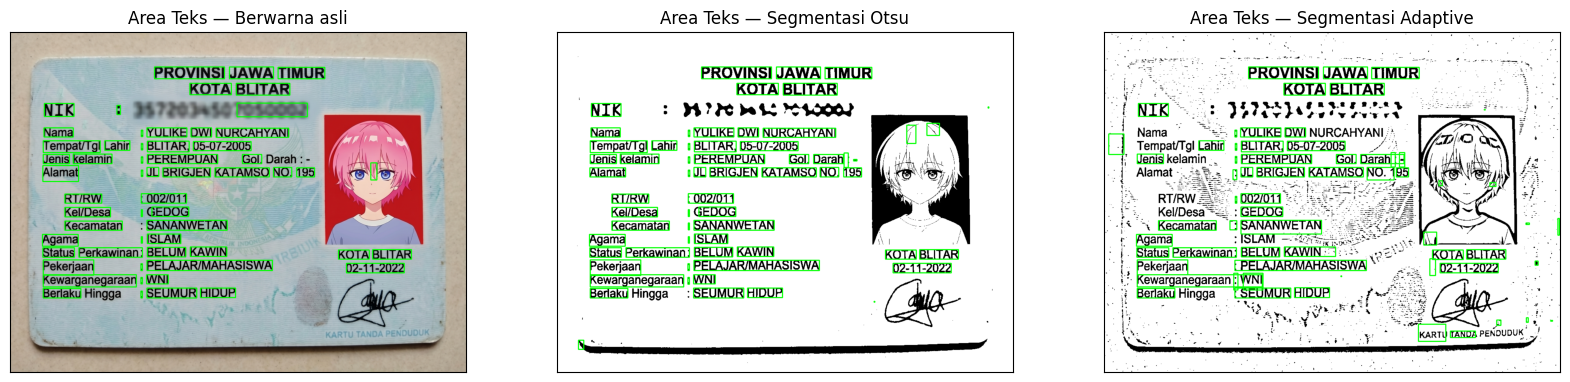

In [ ]:
data_ocr = {}
plt.figure(figsize=(20,7))
for i, (nama, im) in enumerate(citra_ocr.items()):
    d = pytesseract.image_to_data(im, lang=LANG, config=PSM, output_type=Output.DICT)
    data_ocr[nama] = d

    vis = im.copy() if im.ndim == 3 else cv.cvtColor(im, cv.COLOR_GRAY2RGB)
    for j in range(len(d['text'])):
        if d['text'][j].strip() and float(d['conf'][j]) > CONF_MIN:
            x, y, bw, bh = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
            cv.rectangle(vis, (x, y), (x + bw, y + bh), (0, 255, 0), 2)

    plt.subplot(1,3,i+1), plt.imshow(vis)
    plt.title(f'Area Teks — {nama}'), plt.xticks([]), plt.yticks([])
plt.show()

### Langkah 4 – Tabel 10 kata/angka acuan
Isi `acuan` dengan 10 kata atau angka yang terlihat jelas pada KTP masing-masing.
Penilaian memakai seluruh teks hasil OCR (bukan hanya yang berkotak); huruf besar/kecil dan spasi awal/akhir diabaikan.

In [ ]:
acuan = ['PROVINSI', 'JAWA', 'YULIKE', 'BLITAR', 'PEREMPUAN',
         'ISLAM', 'KAWIN', 'MAHASISWA', 'SEUMUR', '3175070101909999']

def norm(s):
    return s.strip().upper()

def daftar_token(teks):
    return [t.strip('.,') for t in re.split(r'[\s:;]+', teks.upper()) if t.strip('.,')]

def cocok(item, teks):
    return norm(item) in daftar_token(teks)

def terbaca_sebagai(item, teks):
    mirip = difflib.get_close_matches(norm(item), daftar_token(teks), n=1, cutoff=0.5)
    return mirip[0] if mirip else '(tidak terbaca)'

baris = []
for no, item in enumerate(acuan, start=1):
    baris.append({
        'No.': no,
        'Teks sebenarnya': item,
        'OCR citra berwarna': terbaca_sebagai(item, hasil_teks['Berwarna asli']),
        'OCR Otsu': terbaca_sebagai(item, hasil_teks['Segmentasi Otsu']),
        'OCR Adaptive': terbaca_sebagai(item, hasil_teks['Segmentasi Adaptive']),
    })
tabel = pd.DataFrame(baris)
display(tabel)

,No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAWA,JAWA,JAWA,JAWA
2,3,YULIKE,YULIKE,YULIKE,YULIKE
3,4,BLITAR,BLITAR,BLITAR,BLITAR
4,5,PEREMPUAN,PEREMPUAN,PEREMPUAN,PEREMPUAN
5,6,ISLAM,ISLAM,ISLAM,HISLAM
6,7,KAWIN,KAWIN,KAWIN,KAWIN
7,8,MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA
8,9,SEUMUR,SEUMUR,SEUMUR,SEUMUR
9,10,3175070101909999,(tidak terbaca),(tidak terbaca),(tidak terbaca)


### Langkah 5 – Persentase kecocokan dan rata-rata confidence

In [ ]:
def rata_confidence(d):
    conf = [float(c) for c, t in zip(d['conf'], d['text']) if t.strip() and float(c) >= 0]
    return sum(conf) / len(conf) if conf else 0.0

ringkas = []
for nama in citra_ocr:
    tepat = sum(cocok(item, hasil_teks[nama]) for item in acuan)
    ringkas.append({
        'Citra masukan OCR': nama,
        'Item terbaca tepat': tepat,
        'Kecocokan (%)': tepat / len(acuan) * 100,
        'Rata-rata confidence': round(rata_confidence(data_ocr[nama]), 2),
    })
ringkasan = pd.DataFrame(ringkas)
display(ringkasan)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,8,80.0,75.81
1,Segmentasi Otsu,8,80.0,72.85
2,Segmentasi Adaptive,7,70.0,43.39


### Pertanyaan analisis


1. Citra dengan pembacaan paling tepat
Berwarna asli dan Segmentasi Otsu seri di 8/10 item (80%). Berwarna asli unggul tipis karena rata-rata confidence-nya lebih tinggi (75,81 vs 72,85). Segmentasi Adaptive paling rendah: 7/10 (70%) dengan confidence 43,39.

2. Kesalahan pembacaan
ISLAM terbaca HISLAM pada citra Adaptive (huruf tambahan akibat noise).
NIK tidak terbaca di ketiga citra. Pada citra berwarna, angkanya abu-abu pucat di atas latar bermotif. Pada Otsu dan Adaptive, angkanya pecah jadi bercak atau titik (terlihat di gambar kotak hijau).
Pada Otsu dan Adaptive, ada kotak hijau palsu di area foto wajah. Pada Adaptive juga ada kotak palsu di tepi kartu, yaitu bintik noise yang dikira teks.

3. Apakah segmentasi selalu meningkatkan OCR?
Tidak. Otsu hanya menyamai citra asli (sama-sama 80%) dan confidence-nya malah lebih rendah. Adaptive lebih buruk dari citra asli, baik kecocokan (70% vs 80%) maupun confidence (43,39 vs 75,81). Pada KTP ini, teks di citra berwarna sudah cukup kontras, jadi thresholding tidak menambah apa-apa.

4. Pengaruh warna dan pola latar
KTP punya latar biru muda bergradasi dengan pola halus (guilloche) dan hologram. Pada Adaptive, pola itu ikut jadi bintik-bintik hitam karena ambang lokal mengikuti variasi kecil di latar. Akibatnya muncul noise, kotak palsu, confidence turun drastis, dan huruf bisa salah baca (HISLAM). Otsu menghapus latar dengan lebih bersih dan teks utama tetap terbaca. Tetapi tulisan yang kontrasnya rendah, seperti NIK, ikut rusak karena satu ambang global tidak cocok untuk semua area. Foto wajah juga menghasilkan deteksi palsu karena garis-garis wajah mirip huruf.

5. Apakah confidence tertinggi = kecocokan tertinggi?
Di percobaan ini ya: Berwarna asli unggul di keduanya (confidence 75,81 dan kecocokan 80%). Tetapi hubungannya tidak mutlak. Otsu punya confidence lebih rendah dari Berwarna asli, tetapi kecocokannya sama (80%). Confidence hanyalah keyakinan mesin yang dirata-ratakan dari semua kata terdeteksi, termasuk noise. Jadi ia tidak menjamin teksnya benar.